# Diffusion Models & Image Generation

**Gudsky Research Foundation · Research Intake 2026 · Day 35**
**Module:** Computer Vision Fundamentals

This notebook is a study companion to the Day 35 guide. It covers the forward diffusion process, the learned reverse process, the noise-prediction training objective, the U-Net backbone, sampling strategies (DDPM, DDIM, distillation), conditioning (classifier-free guidance and cross-attention), latent diffusion, a comparison with GANs (Day 34), and ethics. It ends with a runnable toy diffusion model.

### Learning objectives
- Write the forward noising process and its closed-form shortcut.
- Explain why training reduces to a simple regression on noise.
- Compare DDPM and DDIM sampling, and the speed-quality tradeoff.
- Explain classifier-free guidance and latent diffusion.
- Compare diffusion with GANs on stability, diversity, and speed.

### Contents
1. A second path to generation
2. The forward diffusion process
3. The reverse process and denoising
4. Training a diffusion model
5. U-Net as the denoising backbone
6. Sampling strategies and speed
7. Conditional and guided generation
8. Latent diffusion
9. GANs vs. diffusion
10. Research frontiers and ethics
11. Common pitfalls checklist
12. Glossary
13. Hands-on: a toy diffusion model
14. Derivations and extended notes
15. Practical notes for Colab and a T4 GPU
16. Industry use cases
17. References

## 1. A second path to generation

Day 34 framed generation as learning to produce new samples that look like a training distribution, with no per-input ground truth. GANs solve this with an adversarial game between two networks. Diffusion models solve the same problem with a different mechanism.

- **Forward process:** take a real image and gradually add noise until only static remains.
- **Reverse process:** learn to undo one small step of noise at a time. Starting from pure noise, repeated denoising produces an image.

Generation is an iterative refinement rather than a single forward pass.

## 2. The forward diffusion process

Given a real image $x_0$, the forward process adds a small amount of Gaussian noise at each of $T$ steps:

$$
q(x_t \mid x_{t-1}) = \mathcal{N}\!\left(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\right)
$$

The schedule $\beta_1, \dots, \beta_T$ is fixed in advance. A **linear** schedule increases $\beta_t$ at a constant rate. A **cosine** schedule (Nichol & Dhariwal, 2021) adds noise more slowly near the beginning and end, which avoids degrading the signal too abruptly.

### 2.2 Closed-form sampling of any timestep
Define $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t = \prod_{s=1}^{t} \alpha_s$. Then $x_t$ can be sampled directly from $x_0$:

$$
x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)
$$

Training can therefore jump to a random timestep without simulating every intermediate step. This makes training practical.

The forward process is fixed and has no learned parameters. The only learned part is the reverse process.

## 3. The reverse process and denoising

The reverse process $p_\theta(x_{t-1} \mid x_t)$ is what the model learns. In the common practical formulation, the network $\epsilon_\theta(x_t, t)$ predicts the noise that was added. The reverse step then uses that prediction to move toward a less noisy image.

### 3.1 Connection to score-based modeling
The score of a distribution is $\nabla_x \log p(x)$, a vector field that points toward higher-density regions. Predicting noise is equivalent, up to a known scaling, to estimating this score at each noise level (Song & Ermon, 2019). This is why diffusion and score-based models are two framings of the same idea.

### 3.2 Why one model produces diverse outputs
The model is deterministic given an input. Diversity comes from the random starting noise $x_T$, which leads to different denoising trajectories.

## 4. Training a diffusion model

### 4.1 The simplified training objective
Ho et al. (2020) use this simple loss:

$$
\mathcal{L}_{\text{simple}} = \mathbb{E}_{x_0,\, \epsilon,\, t}\Big[\big\lVert \epsilon - \epsilon_\theta\big(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ t\big) \big\rVert^2\Big]
$$

Each step: sample $x_0$ from the data, sample a random $t$ and noise $\epsilon$, form $x_t$ with the closed form, and regress $\epsilon$. This is a mean-squared-error regression with one network.

Predicting noise rather than the clean image is more stable across timesteps. At early timesteps, $x_t$ is almost $x_0$, so predicting $x_0$ is nearly trivial. At late timesteps, $x_t$ is nearly pure noise, so predicting $x_0$ requires recovering almost everything from almost nothing.

### 4.2 Why training is stable
There is no second network to balance, no adversarial loss whose value fails to indicate progress, and no mode-collapse failure mode from an adversarial game (contrast with Day 34 §3–§4). The loss is a monotone regression signal. Caveat: stability does not guarantee good samples. Sample quality still needs direct inspection.

### 4.3 Training loop
Sample a batch of images; sample an independent random $t$ per image; compute $x_t$; predict $\epsilon$; take an MSE step.

## 5. U-Net as the denoising backbone

Most diffusion implementations use a U-Net (Ronneberger et al., 2015), the same encoder-decoder-with-skip-connections architecture used for segmentation on Day 33. Two additions make it suitable for diffusion:

1. **Timestep embedding.** The network must know which noise level it is denoising. The scalar $t$ is mapped to a vector (commonly sinusoidal, as in Transformer positional encodings) and injected throughout the U-Net.
2. **Attention layers** at the bottleneck and lower-resolution stages. Self-attention lets distant spatial positions interact, which helps globally consistent output (for example, two eyes that are consistent with each other).

## 6. Sampling strategies and speed

### 6.1 DDPM: ancestral sampling
The original DDPM sampler (Ho et al., 2020) steps backward from $t = T$ to $t = 1$. Each step uses the network's noise prediction:

$$
x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t)\right) + \sigma_t z, \qquad z \sim \mathcal{N}(0, I)
$$

With $T \approx 1000$, this means about 1000 sequential network evaluations per sample. The steps depend on each other, so they cannot be run in parallel.

### 6.2 DDIM: deterministic, fewer steps
DDIM (Song et al., 2021) defines a non-Markovian reverse process that allows skipping timesteps. With $\eta = 0$ the sampler is deterministic:

$$
\hat{x}_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}, \qquad
x_{t_{\text{prev}}} = \sqrt{\bar\alpha_{t_{\text{prev}}}}\,\hat{x}_0 + \sqrt{1-\bar\alpha_{t_{\text{prev}}}}\,\epsilon_\theta(x_t,t)
$$

It typically needs tens of steps, not about 1000. The same trained model can be sampled with either sampler. Fixing the starting noise makes DDIM output reproducible, which enables latent interpolation.

### 6.3 Further speedups
Distillation (Salimans & Ho, 2022) trains a student model to match several teacher steps in one step. Consistency models (Song et al., 2023) learn to map any point on the trajectory directly to the clean image, which can give one-step or few-step generation.

### 6.4 The speed-quality tradeoff
Fewer steps means faster sampling and often softer detail or coherence errors. The useful step count is a point on a curve that must be measured for each model and application.

## 7. Conditional and guided generation

### 7.1 Classifier guidance and classifier-free guidance
**Classifier guidance** (Dhariwal & Nichol, 2021) steers sampling with the gradient of a separately trained classifier. That classifier must work on noisy images at every timestep, so it is a bespoke additional model.

**Classifier-free guidance** (Ho & Salimans, 2022) trains one model both with and without the condition (randomly dropping the condition during training). At sampling time, the conditional and unconditional predictions are combined:

$$
\tilde\epsilon = \epsilon_\theta(x_t, t, \varnothing) + w\big(\epsilon_\theta(x_t, t, c) - \epsilon_\theta(x_t, t, \varnothing)\big)
$$

Here $w$ is the guidance scale. Larger $w$ follows the condition more strongly, but very large values can oversaturate outputs. The right value is a tuning choice.

### 7.2 Text conditioning and cross-attention
A text encoder (for example, a CLIP-style encoder) turns the prompt into a sequence of token embeddings. Cross-attention layers in the U-Net let each spatial location attend to these tokens at every denoising step. This is more expressive than the single class-label concatenation used by the conditional GAN on Day 34 §6.

## 8. Latent diffusion

Pixel-space diffusion is expensive: each step runs the U-Net at full resolution, and the cost of each step grows with resolution. Latent diffusion (Rombach et al., 2022) runs the entire diffusion process in the compressed latent space of a pretrained autoencoder:

1. Encode the image: $z = E(x)$.
2. Train and sample the diffusion model in latent space.
3. Decode the final latent: $\hat{x} = D(z_0)$.

The autoencoder is trained beforehand. Its reconstruction quality caps the quality of generated images. Typical autoencoders downsample each spatial dimension by a factor of 8, which reduces spatial positions by 64× and makes high-resolution diffusion practical on single GPUs.

## 9. GANs vs. diffusion

| Dimension | GANs (Day 34) | Diffusion (Day 35) |
|---|---|---|
| Training objective | Adversarial minimax, two networks | Noise regression, one network |
| Training stability | Hard; needs monitoring of failure modes | Generally more stable (see caveat in §4.2) |
| Mode collapse risk | Yes, a known failure mode | Not from an adversarial game; diversity is typically higher |
| Sampling | One forward pass | Many sequential steps (fewer with DDIM or distillation) |
| Speed | Fast | Slower; the main practical drawback |
| Controllability | Conditioning by input concatenation (cGAN) | Classifier-free guidance, cross-attention |
| Practical default today | Specialized, well-tuned domains (e.g., StyleGAN for faces) | Most modern text-to-image systems |

**Practical guidance.** Diffusion is usually preferred when training reliability, diversity, and controllability matter, and when batch or offline generation is acceptable. GANs remain preferable for real-time, single-pass generation, or where a specialized architecture already exists for the domain. There is no universal winner; the choice depends on constraints.

Figures in the source guide use qualitative comparisons only. Quantitative claims (such as FID comparisons) require measured results with citations.

## 10. Research frontiers and ethics

**Consistency models** (Song et al., 2023) push distillation toward one-step generation while preserving some of diffusion's training stability. This is an active research direction. Whether it closes the speed gap with GANs at scale is an open question.

**Video diffusion** adds temporal attention or 3D convolutions so that consecutive frames stay consistent. Naive per-frame denoising causes flicker.

**3D-aware diffusion** generates content consistent with an underlying 3D structure, often learned from multi-view 2D images.

**Beyond images.** Diffusion has been applied to audio (with 1D or spectrogram-based backbones) and molecular structure generation (with graph-structured architectures). The forward and reverse framework stays the same; the backbone changes.

**Ethics.** Diffusion inherits the deepfake and consent concerns from Day 34 §10.2. Text conditioning makes the space of possible requests much larger, so prompt-level safeguards (filtering or refusing disallowed requests before generation) complement output-level detection and disclosure. Label synthetic content clearly and do not generate identifiable depictions of real people without explicit permission.

## 11. Common pitfalls: debugging checklist

- [ ] Verify the closed-form $x_t$ computation (§2.2). A bug here corrupts every training target while the loss still decreases.
- [ ] Confirm the timestep embedding reaches every part of the U-Net, not only the input layer.
- [ ] Distinguish a training problem from the expected effect of too few sampling steps. Blurry output from an aggressively low step count is not necessarily a training bug.
- [ ] Check the classifier-free guidance scale before concluding conditioning has failed.
- [ ] For latent diffusion, check the autoencoder's reconstruction quality independently.
- [ ] Use one noise-prediction convention (predict $\epsilon$ or predict $x_0$) consistently across training and sampling.
- [ ] When comparing DDPM and DDIM, use the same trained model and vary only the sampler.
- [ ] Fix all seeds (training noise, random timesteps, and the starting noise $x_T$) when comparing runs.
- [ ] Do not compare small-scale FID against published benchmark numbers computed under different conditions.

### Reproducibility
Diffusion training adds a random timestep per example and random noise per timestep to the usual sources of randomness. Sampling adds the starting noise $x_T$, which determines the output image.

## 12. Glossary

| Term | Definition |
|---|---|
| **Forward process** | Fixed, non-learned Markov chain that adds Gaussian noise over $T$ steps. |
| **Noise schedule** | Sequence $\beta_1,\dots,\beta_T$ controlling how much noise each step adds (linear or cosine). |
| **Reverse process** | Learned denoising procedure that starts from noise and recovers an image. |
| **Noise prediction** | Network output $\epsilon_\theta(x_t, t)$ estimating the noise added to $x_t$. |
| **Score function** | Gradient of the log-density; noise prediction is equivalent up to scaling. |
| **DDPM** | Original diffusion sampler with about 1000 sequential steps. |
| **DDIM** | Faster, deterministic (with $\eta = 0$) sampler that allows skipping steps. |
| **Timestep embedding** | Vector representation of $t$ injected into the U-Net. |
| **Classifier guidance** | Steering sampling with the gradient of a separate noise-aware classifier. |
| **Classifier-free guidance** | Steering sampling by combining conditional and unconditional predictions from one model. |
| **Cross-attention conditioning** | U-Net layers that attend to condition tokens (e.g., text embeddings). |
| **Latent diffusion** | Diffusion run in the compressed latent space of a pretrained autoencoder. |
| **Consistency model** | Model trained to map any point on a noising trajectory directly to the clean image. |
| **Distillation** | Training a faster student to reproduce several steps of a teacher in fewer steps. |

## 13. Hands-on: a toy diffusion model

This experiment uses the same 1-D target as the Day 34 toy GAN: a mixture of two Gaussians centered at −2 and +2. It runs on CPU in about a minute, and on a GPU if one is available.

It trains a noise-prediction network, then compares two samplers on the same trained model:
- **DDPM**, with all $T$ steps.
- **DDIM**, deterministic, with far fewer steps.

Measured results come from running the code. The mode-coverage fraction should be near 0.5 if both modes are learned.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

T = 200                                          # diffusion steps
betas = torch.linspace(1e-4, 0.05, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)         # \bar{alpha}_t

def sample_real(n: int) -> torch.Tensor:
    # Mixture of two Gaussians, modes at -2 and +2 (std 0.3).
    component = torch.randint(0, 2, (n, 1)).float()
    return component * 4.0 - 2.0 + 0.3 * torch.randn(n, 1)

def features(x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    # Input: the noisy sample plus a sinusoidal timestep embedding.
    tf = t.float().unsqueeze(1) / T
    freqs = torch.arange(1, 5, device=x.device).float() * math.pi
    ang = tf * freqs
    return torch.cat([x, torch.sin(ang), torch.cos(ang)], dim=1)

class EpsNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(9, 128), nn.SiLU(),
            nn.Linear(128, 128), nn.SiLU(),
            nn.Linear(128, 1),
        )
    def forward(self, x, t):
        return self.net(features(x, t))

model = EpsNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

BATCH = 256
STEPS = 4000
losses = []

for step in range(STEPS):
    x0 = sample_real(BATCH).to(device)
    t = torch.randint(0, T, (BATCH,), device=device)     # independent t per example
    eps = torch.randn_like(x0)
    ab = alpha_bar[t].unsqueeze(1)
    xt = torch.sqrt(ab) * x0 + torch.sqrt(1.0 - ab) * eps   # closed-form forward sample
    loss = ((model(xt, t) - eps) ** 2).mean()               # simplified objective
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

print(f"Trained {STEPS} steps on {device}. Final loss (avg last 200): {np.mean(losses[-200:]):.4f}")

Trained 4000 steps on cuda. Final loss (avg last 200): 0.3516


Real  : mean=+0.043  std=2.021  fraction<0=0.490
DDPM  : mean=+0.050  std=1.998  fraction<0=0.488
DDIM  : mean=+0.042  std=1.966  fraction<0=0.489
Steps: DDPM = 200 network evaluations per sample; DDIM = 20.
Mode-coverage check: a fraction near 0.5 means both modes are covered.


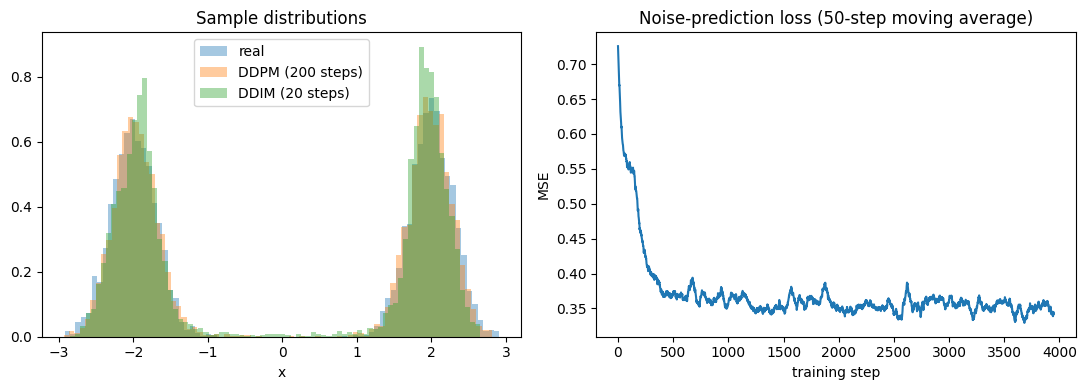

In [2]:
@torch.no_grad()
def sample_ddpm(n: int) -> torch.Tensor:
    # Ancestral sampling over all T steps (DDPM).
    x = torch.randn(n, 1, device=device)
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        mean = (x - betas[t] / torch.sqrt(1.0 - alpha_bar[t]) * eps) / torch.sqrt(alphas[t])
        if t > 0:
            # Posterior variance (Ho et al., 2020).
            beta_tilde = betas[t] * (1.0 - alpha_bar[t - 1]) / (1.0 - alpha_bar[t])
            x = mean + torch.sqrt(beta_tilde) * torch.randn_like(x)
        else:
            x = mean
    return x

@torch.no_grad()
def sample_ddim(n: int, num_steps: int, x_init: torch.Tensor = None) -> torch.Tensor:
    # Deterministic DDIM (eta = 0) on an evenly spaced subsequence of timesteps.
    taus = torch.linspace(0, T - 1, num_steps, device=device).round().long()
    x = torch.randn(n, 1, device=device) if x_init is None else x_init.clone()
    for i in reversed(range(num_steps)):
        t = int(taus[i])
        t_prev = int(taus[i - 1]) if i > 0 else -1
        ab_t = alpha_bar[t]
        ab_prev = alpha_bar[t_prev] if t_prev >= 0 else torch.tensor(1.0, device=device)
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        x0_hat = (x - torch.sqrt(1.0 - ab_t) * eps) / torch.sqrt(ab_t)
        x = torch.sqrt(ab_prev) * x0_hat + torch.sqrt(1.0 - ab_prev) * eps
    return x

model.eval()
N = 5000
ddpm_samples = sample_ddpm(N).cpu().numpy().ravel()
ddim_samples = sample_ddim(N, num_steps=20).cpu().numpy().ravel()
real_samples = sample_real(N).numpy().ravel()

def summarize(name, s):
    print(f"{name:<6}: mean={s.mean():+.3f}  std={s.std():.3f}  fraction<0={(s < 0).mean():.3f}")

summarize("Real", real_samples)
summarize("DDPM", ddpm_samples)
summarize("DDIM", ddim_samples)
print(f"Steps: DDPM = {T} network evaluations per sample; DDIM = 20.")
print("Mode-coverage check: a fraction near 0.5 means both modes are covered.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(real_samples, bins=80, density=True, alpha=0.4, label="real")
axes[0].hist(ddpm_samples, bins=80, density=True, alpha=0.4, label="DDPM (200 steps)")
axes[0].hist(ddim_samples, bins=80, density=True, alpha=0.4, label="DDIM (20 steps)")
axes[0].set_title("Sample distributions"); axes[0].set_xlabel("x"); axes[0].legend()
axes[1].plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
axes[1].set_title("Noise-prediction loss (50-step moving average)")
axes[1].set_xlabel("training step"); axes[1].set_ylabel("MSE")
plt.tight_layout()
plt.show()

### Exercises
1. Change the number of DDIM steps to 5, 10, 50, and 200. At what step count does the distribution start to degrade? Plot fraction<0 and the standard deviation against step count.
2. Replace the linear schedule with a cosine schedule (Nichol & Dhariwal, 2021). Does the trained model change behavior?
3. Train with a timestep embedding removed (set `features` to return only `x`). Which sampler fails first, and why?
4. Fix the starting noise and compare DDIM outputs across two runs of the same trained model. Then compare DDPM outputs. Explain the difference.
5. Compare the training loss at early and late timesteps. Relate the result to the argument in §4.1.

## 14. Derivations and extended notes

### 14.1 The posterior $q(x_{t-1} \mid x_t, x_0)$
Training and the DDPM sampler rely on the **true** reverse conditional, which is tractable when $x_0$ is known. Combining the forward Markov step with the closed form gives a Gaussian:

$$
q(x_{t-1} \mid x_t, x_0) = \mathcal{N}\big(x_{t-1};\ \tilde\mu_t(x_t, x_0),\ \tilde\beta_t I\big)
$$

$$
\tilde\mu_t(x_t, x_0) = \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0 + \frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t, \qquad
\tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t
$$

The model's reverse step $p_\theta(x_{t-1} \mid x_t)$ is trained to match this target. Substituting $x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\epsilon)/\sqrt{\bar\alpha_t}$ into $\tilde\mu_t$ gives the noise-parameterized mean used in §6.1.

### 14.2 From the variational bound to the simple loss
Diffusion models are trained by maximizing a variational lower bound on $\log p_\theta(x_0)$. The bound decomposes into one KL term per timestep:

$$
L_{\text{vlb}} = L_T + \sum_{t>1} L_{t-1} + L_0, \qquad L_{t-1} = D_{\text{KL}}\big(q(x_{t-1}\mid x_t, x_0)\,\Vert\, p_\theta(x_{t-1}\mid x_t)\big)
$$

Each $L_{t-1}$ is a weighted squared error on the noise prediction, with a timestep-dependent weight that is close to $\beta_t^2 / (2\sigma_t^2 \alpha_t (1-\bar\alpha_t))$ under the common choice of variance. Ho et al. (2020) found that dropping this weight and using the unweighted $\mathcal{L}_{\text{simple}}$ from §4.1 gave better sample quality in practice, even though it no longer matches the bound exactly. This is an empirical choice, not a theorem.

### 14.3 DDIM with stochasticity $\eta$
DDIM is a family of samplers indexed by $\eta \ge 0$. The noise injected at each step is

$$
\sigma_t(\eta) = \eta \sqrt{\frac{1-\bar\alpha_{t_{\text{prev}}}}{1-\bar\alpha_t}}\sqrt{1 - \frac{\bar\alpha_t}{\bar\alpha_{t_{\text{prev}}}}}
$$

$\eta = 0$ gives the deterministic sampler in §6.2. $\eta = 1$ recovers a DDPM-like stochastic sampler. Intermediate values trade determinism against diversity.

### 14.4 Cosine schedule
Nichol & Dhariwal (2021) define the schedule through the cumulative signal level:

$$
\bar\alpha_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\right), \qquad \beta_t = \min\big(1 - \bar\alpha_t/\bar\alpha_{t-1},\ 0.999\big)
$$

The offset $s$ is a small constant (0.008 in the original paper). The clipping at 0.999 acts near $t = T$, where $\bar\alpha_t$ approaches zero and the raw ratio can become unstable; the printed values in the next cell show β reaching the clip at the final step. The next cell checks the closed form numerically and computes the cosine schedule.

### 14.5 Common misconceptions
- *"The model learns the forward process."* It does not. The forward process is fixed. Only $\epsilon_\theta$ is learned.
- *"More sampling steps always means better images."* Beyond a point, extra steps add cost with little visible gain. The useful count is found by measurement.
- *"Diffusion always beats GANs."* Each family has strengths for different constraints (§9).
- *"The loss going down means samples are good."* The MSE on noise can fall while sample quality plateaus. Inspect samples.

In [ ]:
# Numerical check of the closed form and the cosine schedule.
import math
import torch

torch.manual_seed(0)
T_check = 200
betas_lin = torch.linspace(1e-4, 0.05, T_check, dtype=torch.float64)
alpha_bar_lin = torch.cumprod(1.0 - betas_lin, dim=0)

# Iterate the forward Markov chain for many samples and compare to the closed form.
n = 200_000
x0 = torch.full((n,), 1.5, dtype=torch.float64)
x = x0.clone()
t_check = 50
for t in range(t_check + 1):           # x becomes x_{t_check}
    if t == 0:
        continue
    a = 1.0 - betas_lin[t - 1]
    x = torch.sqrt(a) * x + torch.sqrt(betas_lin[t - 1]) * torch.randn(n, dtype=torch.float64)

ab = alpha_bar_lin[t_check - 1]        # index shift: alpha_bar at step t_check
print(f"Iterated chain : mean={x.mean():.4f}  var={x.var():.4f}")
print(f"Closed form    : mean={(torch.sqrt(ab) * 1.5):.4f}  var={(1 - ab):.4f}")

# Cosine schedule (Nichol & Dhariwal, 2021).
def cosine_betas(T: int, s: float = 0.008, max_beta: float = 0.999):
    def f(t):
        return math.cos(((t / T) + s) / (1 + s) * math.pi / 2) ** 2
    ab = [f(t) / f(0) for t in range(T + 1)]
    return [min(1 - ab[t + 1] / ab[t], max_beta) for t in range(T)]

cb = torch.tensor(cosine_betas(200), dtype=torch.float64)
print("\nLinear vs cosine beta (selected steps):")
for t in [0, 50, 100, 150, 199]:
    print(f"  t={t:3d}  linear={betas_lin[t]:.5f}  cosine={cb[t]:.5f}")

## 15. Practical notes for Colab and a T4 GPU

**Setup.** In Colab, choose Runtime → Change runtime type → T4 GPU, then check `torch.cuda.is_available()`. The toy model in §13 runs on either device without changes.

**What a T4 (16 GB VRAM) is realistic for:**
- **Toy and small pixel-space experiments** (1-D or 32×32 images): training from scratch is feasible in minutes to hours.
- **Inference with pretrained latent diffusion models:** a T4 can typically generate images with the released Stable Diffusion family, usually in half precision (FP16). Check the model's memory requirements before starting.
- **Training from scratch at high resolution or on large datasets:** generally not practical on a single T4 within a Colab session. Fine-tuning a small pretrained model on a small dataset is the realistic option.

**Practical tips:**
- Use mixed precision (`torch.autocast`, FP16) for training and inference. T4 Tensor Cores support FP16 well.
- Save checkpoints and sample grids to Google Drive, because Colab sessions disconnect.
- Measure sampling time per image for each sampler and step count. Report these measurements, not estimates.
- Pretrained weights have their own licenses and usage terms. Read them before using or redistributing a checkpoint.

**Tooling.** The Hugging Face `diffusers` library provides standard implementations of schedulers (`DDPMScheduler`, `DDIMScheduler`) and pipelines for pretrained models. Use it for practical experiments after the mechanics in this notebook are clear. Check the current API documentation, because the library changes frequently.

## 16. Industry use cases
- **Text-to-image generation:** the mainstream application of latent diffusion with cross-attention conditioning and classifier-free guidance (§7–8).
- **Inpainting and editing:** regenerating masked regions of a photo while keeping the rest.
- **Super-resolution and restoration:** conditioning a diffusion model on a low-resolution or degraded input.
- **Audio and speech generation:** diffusion over spectrograms or waveform representations (§10.4).
- **Molecular and materials design:** diffusion over graph-structured molecular data (§10.4), an active research area.

For each use case, check the current literature and the deployed systems' documentation rather than relying on this summary, since the field changes quickly.

## 17. References

Primary sources for the methods in this notebook. Verify bibliographic details before citing them in submitted work.

1. Sohl-Dickstein, J. et al. (2015). *Deep Unsupervised Learning using Nonequilibrium Thermodynamics.* ICML. arXiv:1503.03585.
2. Song, Y. & Ermon, S. (2019). *Generative Modeling by Estimating Gradients of the Data Distribution.* NeurIPS. arXiv:1907.05600.
3. Ho, J., Jain, A. & Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS. arXiv:2006.11239.
4. Song, J., Meng, C. & Ermon, S. (2021). *Denoising Diffusion Implicit Models.* ICLR. arXiv:2010.02502.
5. Nichol, A. & Dhariwal, P. (2021). *Improved Denoising Diffusion Probabilistic Models.* ICML. arXiv:2102.09672. (Cosine schedule.)
6. Dhariwal, P. & Nichol, A. (2021). *Diffusion Models Beat GANs on Image Synthesis.* NeurIPS. arXiv:2105.05233. (Classifier guidance.)
7. Ho, J. & Salimans, T. (2022). *Classifier-Free Diffusion Guidance.* arXiv:2207.12598.
8. Rombach, R. et al. (2022). *High-Resolution Image Synthesis with Latent Diffusion Models.* CVPR. arXiv:2112.10752.
9. Salimans, T. & Ho, J. (2022). *Progressive Distillation for Fast Sampling of Diffusion Models.* ICLR. arXiv:2202.00512.
10. Song, Y. et al. (2023). *Consistency Models.* ICML. arXiv:2303.01469.
11. Ronneberger, O., Fischer, P. & Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI. arXiv:1505.04597.